# Research Activity II

**Objective:** Create an example to generate anomalies on surfaces. For example, the MVTec AD Dataset contains samples of defects
applied to train defect’s detection models for AI visual inspections. This research activity aims to create synthetic defects in
surface images to be used in anomaly detection. Thus, choose one kind of defect that you prefer to be automatically created
(cracks, stains, discoloration, etc.) and try to generate this defect on any surface.

This experiment uses the Tile category from the MVTec AD dataset, with the following images:
- `train/good/003.png` — original, defect-free surface. This is the only source image to be edited.
- `test/crack/003.png` — a *different* tile with a real crack, used only for visual comparison. The two images are not pixel-aligned ground-truth pairs.



## 1. Configure Colab and Download the Images

In this step, Google Colab is configured to use a T4 GPU to support Stable Diffusion Inpainting. The model processes images at a resolution of 512 × 512 pixels to reduce GPU memory requirements. The input images are automatically downloaded from my [GitHub repository](https://github.com/Alejandro257/synthetic-anomaly-research/tree/main/images) and loaded for the synthetic defect generation process.

In [17]:
# Install the libraries used for diffusion inpainting.
# Do not install torchao; it is not needed for this exercise.
%pip -q install diffusers transformers accelerate safetensors opencv-python-headless scikit-image


In [18]:

import requests
from pathlib import Path
from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity

# Reproducible experiment settings
SEED = 2026
OUTPUT_DIR = Path("MVTec_Tile_003_AI_Results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# GitHub repository
BASE_URL = (
    "https://raw.githubusercontent.com/"
    "Alejandro257/synthetic-anomaly-research/main/images"
)

# Input images
filenames = [
    "tile_good_003.png",
    "tile_real_crack_003.png"
]

# Download images automatically
for filename in filenames:
    url = f"{BASE_URL}/{filename}"
    response = requests.get(url, timeout=30)
    response.raise_for_status()

    Path(filename).write_bytes(response.content)
    print(f"Downloaded: {filename}")

# Load images as NumPy arrays
original = np.array(
    Image.open("tile_good_003.png").convert("RGB")
)

real_reference = np.array(
    Image.open("tile_real_crack_003.png").convert("RGB")
)

print("Images loaded successfully.")
print("Original image:", original.shape)
print("Real crack image:", real_reference.shape)


import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE != "cuda":
    raise RuntimeError("Select a GPU runtime in Google Colab before running the diffusion model.")


Downloaded: tile_good_003.png
Downloaded: tile_real_crack_003.png
Images loaded successfully.
Original image: (840, 840, 3)
Real crack image: (840, 840, 3)
Device: cuda


## 2. Inspect the Normal and Real-Defect Examples

In this step, the original defect-free tile and the image containing a real crack are visually examined. The real crack serves as a qualitative reference to observe characteristics such as shape, thickness, and branching. This reference is used to guide the generation of the synthetic defect, without copying any pixels from the real crack image.

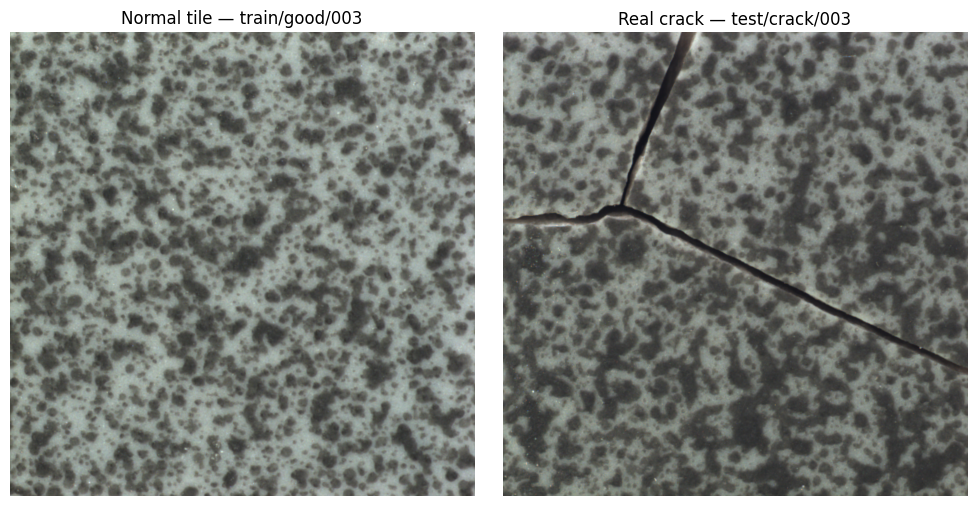

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, im, title in zip(axes, [original, real_reference],
                          ['Normal tile — train/good/003', 'Real crack — test/crack/003']):
    ax.imshow(im)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. Create a Crack-Shaped Guide Mask

In this step, a crack-shaped mask is generated using a procedural algorithm to define the region where the synthetic defect will be created. The algorithm produces an irregular path with varying thickness and branches. The mask is slightly expanded to provide enough space for Stable Diffusion Inpainting to generate the crack details. The white regions indicate where the AI model can modify the image, while the black regions preserve the original tile surface.

In [20]:
def synthesize_crack(image, seed=2026, branching=True):
    """Inject a procedural branched crack and independently return its support mask.

    Uses only the normal image and random generator; the real-defect reference
    is not read by this function. Works on uint8 RGB images.
    """
    rng = np.random.default_rng(seed)
    h,w = image.shape[:2]
    if h<160 or w<160:
        raise ValueError('Expected a surface image of at least 160 x 160 pixels.')
    scale = min(h,w) / 840.0
    # Vary junction position and branch angles instead of copying the real sample.
    pivot=np.array([rng.uniform(.35,.54)*w,rng.uniform(.36,.56)*h],dtype=np.float64)
    directions=np.deg2rad([rng.uniform(165,202),rng.uniform(257,304),rng.uniform(13,48)])
    core_layer=np.zeros((h,w),dtype=np.uint8)
    edge_layer=np.zeros((h,w),dtype=np.uint8)
    lip_layer=np.zeros((h,w),dtype=np.uint8)
    paths=[]

    def path(start, angle, length, n=205):
        t=np.linspace(0.0,1.0,n)
        # Gently change the direction with distance.
        bend=rng.uniform(-.23,.23)*t*t*length
        normal=np.array([-np.sin(angle),np.cos(angle)])
        heading=np.array([np.cos(angle),np.sin(angle)])
        # Correlated irregularity of several sizes; ends remain connected to start.
        frequencies=[2,5,11,24]
        wav=np.zeros_like(t)
        for f,a in zip(frequencies,[6.0,2.7,1.4,.65]):
            phase=rng.uniform(0,2*np.pi)
            wav += a*np.sin(2*np.pi*f*t+phase) - a*np.sin(phase)*(1-t)
        wav *= scale
        pts=start[None,:]+t[:,None]*length*heading[None,:]+(bend+wav)[:,None]*normal[None,:]
        return pts

    def draw_path(points, width_px, branch=False, widened_section=False):
        n=len(points)
        common=rng.normal(0, .75)
        u=np.linspace(0,1,n)
        smooth= .9*np.sin(2*np.pi*u*rng.uniform(2.0,4.0)+rng.uniform(0,6))
        widths=(width_px*scale*(.78+.2*np.sin(np.pi*u)+.11*smooth + .06*common))
        if branch:
            widths *= .9 - .55*u
        elif widened_section:
            widths *= (1 + 1.15*np.exp(-((u-.43)/.14)**2))
        else:
            # Primary cracks have broad sections, narrow tips.
            widths *= .97 - .35*np.maximum(0,(u-.80)/.20)
        widths=np.clip(widths, 1.0, 18*scale)
        for k in range(n-1):
            p=tuple(np.rint(points[k]).astype(int));q=tuple(np.rint(points[k+1]).astype(int))
            ww=max(1,int(round(widths[k])))
            cv2.line(edge_layer,p,q,255,ww+max(2,int(4*scale)),cv2.LINE_AA)
            cv2.line(core_layer,p,q,255,ww,cv2.LINE_AA)
            # Small light-colored rough boundary mainly on upper-left side.
            shift=max(1,int(round(1.6*scale)))
            lp=(p[0]-shift,p[1]-shift);lq=(q[0]-shift,q[1]-shift)
            cv2.line(lip_layer,lp,lq,255,ww+max(1,int(2*scale)),cv2.LINE_AA)
        paths.append(points)

    lengths=[1.2*max(w,h)]*3
    for i,ang in enumerate(directions):
        points=path(pivot,ang,lengths[i])
        draw_path(points,width_px=rng.uniform(8.2,11.6),widened_section=(i==1))
    if branching:
        # Minor offshoots, shorter and thinner than the main fractures.
        for i in [1,2]:
            anchor_index=int(rng.integers(27,59))
            anchor=paths[i][anchor_index]
            heading=directions[i]+rng.choice([-1,1])*rng.uniform(.50,1.07)
            branch_path=path(anchor,heading,rng.uniform(.13,.21)*max(h,w),n=110)
            draw_path(branch_path,width_px=rng.uniform(2.4,4.5),branch=True)

    # Masks/edges derived from geometry, not from a difference of output and input.
    core=cv2.GaussianBlur(core_layer.astype(np.float32)/255, (3,3), .55*scale)
    rim=cv2.GaussianBlur(edge_layer.astype(np.float32)/255, (5,5), 1.0*scale)
    lip=cv2.GaussianBlur(lip_layer.astype(np.float32)/255, (3,3),.6*scale)
    # Edge remains slightly transparent, dark center resembles fracture void.
    shadow=np.clip(.76*core+.105*rim,0,.90)
    # Lip visible primarily on one side of the crack: 0 where core is fully dark.
    bright=.14*lip*(1-np.clip(core,0,1))
    # Geometry-defined support includes all three effects; zero outside it.
    support=(core_layer>0)|(edge_layer>0)|(lip_layer>0)
    base=image.astype(np.float32)
    # Blend a subdued charcoal core to retain tile's visual texture.
    shadow_color=np.array([11.0,12.0,14.0],dtype=np.float32)
    result=base*(1-shadow[...,None])+shadow[...,None]*shadow_color
    result += bright[...,None]*23.0
    modified=np.where(support[...,None],np.clip(np.rint(result),0,255),base).astype(np.uint8)
    mask=support.astype(np.uint8)*255
    return modified,mask


## 4. Generate the Synthetic Crack with Stable Diffusion Inpainting

In this step, we use a pretrained Stable Diffusion Inpainting model to generate a synthetic crack on the original defect-free tile. The model receives the original image, a crack-shaped mask, and a text prompt describing the desired defect. The image is resized to 512 × 512 pixels for processing, and the AI-generated region is then integrated into the original 840 × 840 image, preserving the surrounding surface. This approach combines procedural mask generation with AI-based defect synthesis.

In [23]:


from diffusers import AutoPipelineForInpainting

MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-inpainting"

IMAGE_SIZE = 512
MASK_MARGIN = 6

# Load pretrained diffusion model
pipe = AutoPipelineForInpainting.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    variant="fp16",
    use_safetensors=True,
).to("cuda")

# Description of the synthetic defect
PROMPT = (
    "Macro photograph of a gray speckled ceramic tile "
    "with a clearly visible deep black fracture, "
    "continuous dark jagged crack with three branching paths, "
    "uneven thickness, irregular broken edges, "
    "subtle shadows inside the fracture, "
    "natural chipped ceramic edges, "
    "realistic industrial surface damage, "
    "preserved granular gray tile texture"
)

NEGATIVE_PROMPT = (
    "blurry crack, faint crack, invisible fracture, "
    "smooth decorative lines, painted lines, "
    "cartoon, illustration, artificial pattern, "
    "glossy surface, watermark, text"
)


def generate_ai_crack(normal_rgb: np.ndarray, seed: int = 2026):
    """
    Generate a synthetic crack using diffusion inpainting
    and a procedurally defined guide mask.
    """

    # Generate procedural crack geometry
    procedural_rgb, narrow_mask = synthesize_crack(
        normal_rgb, seed=seed
    )

    # Expand the mask for diffusion inpainting
    kernel_size = MASK_MARGIN * 2 + 1

    edit_mask = cv2.dilate(
        narrow_mask,
        cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (kernel_size, kernel_size)
        )
    )

    edit_mask = (edit_mask > 0).astype(np.uint8) * 255

    h, w = normal_rgb.shape[:2]

    # Prepare images for Stable Diffusion
    init_image = Image.fromarray(normal_rgb).resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.LANCZOS
    )

    mask_image = Image.fromarray(edit_mask).resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.NEAREST
    )

    # AI-based defect generation
    generator = torch.Generator(
        device="cuda"
    ).manual_seed(seed)

    with torch.inference_mode():
        inpainted = pipe(
            prompt=PROMPT,
            negative_prompt=NEGATIVE_PROMPT,
            image=init_image,
            mask_image=mask_image,
            strength=0.90,
            num_inference_steps=40,
            guidance_scale=9.5,
            generator=generator,
        ).images[0]

    # Restore original image resolution
    ai_rgb = np.asarray(
        inpainted.resize(
            (w, h),
            Image.Resampling.BICUBIC
        )
    )

    # Blend AI-generated region with original image
    alpha = cv2.GaussianBlur(
        (edit_mask > 0).astype(np.float32),
        (11, 11),
        sigmaX=2
    )

    alpha *= (edit_mask > 0)

    original_f = normal_rgb.astype(np.float32)
    ai_f = ai_rgb.astype(np.float32)

    blended = (
        original_f * (1 - alpha[..., None])
        + ai_f * alpha[..., None]
    )

    # Reinforce the fracture core using procedural geometry
    procedural_f = procedural_rgb.astype(np.float32)

    core_region = narrow_mask > 0

    # Preserve the darker pixels of the procedural fracture
    blended[core_region] = np.minimum(
        blended[core_region],
        procedural_f[core_region]
    )

    # Convert the result to uint8
    result = np.clip(
        np.rint(blended), 0, 255
    ).astype(np.uint8)

    # Preserve all pixels outside the edit mask
    result[edit_mask == 0] = normal_rgb[edit_mask == 0]

    return result, edit_mask


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

In [24]:
synthetic, synthetic_mask = generate_ai_crack(original, seed=SEED)
assert original.shape == synthetic.shape
assert synthetic_mask.shape == original.shape[:2]
assert np.array_equal(original[synthetic_mask == 0], synthetic[synthetic_mask == 0])

Image.fromarray(original).save(OUTPUT_DIR / "tile_good_003.png")
Image.fromarray(synthetic).save(OUTPUT_DIR / "tile_ai_crack_003.png")
Image.fromarray(synthetic_mask).save(OUTPUT_DIR / "tile_ai_mask_003.png")
Image.fromarray(real_reference).save(OUTPUT_DIR / "tile_real_crack_003_reference.png")
print("AI-based crack generated with seed:", SEED)


  0%|          | 0/36 [00:00<?, ?it/s]

AI-based crack generated with seed: 2026


## 5. Compare the Images

In this step, we compare four images: (A) the original defect-free tile, (B) the synthetic crack generated using Stable Diffusion Inpainting, (C) the mask defining the modified region, and (D) a real crack from the MVTec AD dataset used as a visual reference. This comparison allows us to examine the generated defect and its visual characteristics relative to a real crack.

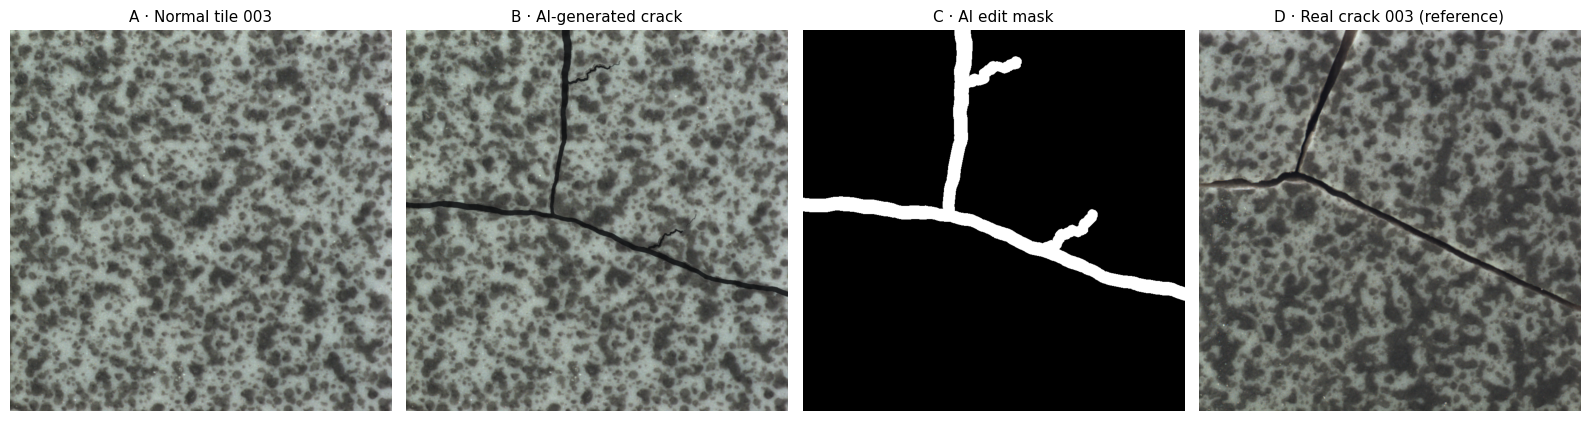

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
imgs = [original, synthetic, synthetic_mask, real_reference]
names = ['A · Normal tile 003', 'B · AI-generated crack',
         'C · AI edit mask', 'D · Real crack 003 (reference)']
for ax, img, name in zip(axes, imgs, names):
    if img.ndim == 2:
        ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    else:
        ax.imshow(img)
    ax.set_title(name, fontsize=11)
    ax.axis('off')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'comparison_ai_tile_003.png', dpi=185, bbox_inches='tight')
plt.show()

## 6. Pixel-Level Comparison

In this step, we evaluate the synthetic crack by comparing the original image with the AI-generated result. We calculate the **mask area** to determine the percentage of the surface selected for modification, the **Mean Absolute Error (MAE)** inside and outside the mask to measure pixel-level changes, and the **Structural Similarity Index (SSIM)** to assess the overall similarity between both images. These metrics allow us to quantify the generated changes and verify that the original surface remains unchanged outside the defect region.

In [26]:
pixel_difference = np.abs(synthetic.astype(np.float32) - original.astype(np.float32))
inside = synthetic_mask > 0
assert inside.any() and (~inside).any()
mask_area = 100 * inside.mean()
changed_pixels = 100 * np.any(synthetic != original, axis=2).mean()
mae_outside = float(pixel_difference[~inside].mean())
mae_inside = float(pixel_difference[inside].mean())
ssim = structural_similarity(original, synthetic, channel_axis=2, data_range=255)

print(f'Mask area: {mask_area:.2f}%')
print(f'Pixels actually changed: {changed_pixels:.2f}%')
print(f'MAE outside mask: {mae_outside:.2f} / 255')
print(f'MAE inside mask: {mae_inside:.2f} / 255')
print(f'Global SSIM: {ssim:.4f}')

metrics = {'mask_area_pct': float(mask_area),
           'changed_pixels_pct': float(changed_pixels),
           'mae_outside': mae_outside, 'mae_inside': mae_inside,
           'ssim': float(ssim)}

Mask area: 6.27%
Pixels actually changed: 6.22%
MAE outside mask: 0.00 / 255
MAE inside mask: 44.38 / 255
Global SSIM: 0.9528


## 7. Results and Discussion

This experiment combines procedural mask generation with Stable Diffusion Inpainting to create a synthetic crack on a defect-free tile surface. The resulting image is evaluated using MAE, SSIM, and the percentage of the masked area to quantify pixel-level modifications and verify the preservation of the surrounding surface.

The generated crack is also visually compared with a real defect from the MVTec AD dataset, considering its shape, continuity, thickness, and contrast. This comparison provides a qualitative assessment of the synthetic defect.

The approach demonstrates how generative AI can be applied to synthetic defect creation, although the crack geometry is defined procedurally rather than learned by the diffusion model.

**Dataset reference:** Bergmann et al. (2019), *MVTec AD — A Comprehensive Real-World Dataset for Unsupervised Anomaly Detection*. [Official dataset](https://www.mvtec.com/research-teaching/datasets/mvtec-ad).